# Sensitivity analysis

1. **Optimal plane:** `run_pipeline(base)` sizes the plane for mission range + reserve and feeds the OpenVSP parasite drag back until it settles.
2. **One-at-a-time sweeps:** starting from that plane, one parameter is changed while everything else stays at its optimum, and the pipeline is run again.
3. **Two plots per sweep:**
   - **Range** with the fuel fixed at the optimal plane's fuel mass: how far does that tank get?
   - **Required fuel** [kg] for mission range + reserve, shown between 5 and 10 kg.

Cases where the mission can't be reached or the iteration doesn't converge are left out of the curves. Every case runs OpenVSP 2–3 times (~1.3 s each), so the sweeps take several minutes; lower `N_POINTS` for a quick look.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

import ardea_sizer as az
from ardea_sizer.pipeline import evaluate_from_fuel_mass
 
FUEL_YLIM = (5.0, 10.0)  # kg, y-axis of the required-fuel plot
N_POINTS = 8            # per sweep

## 1. Optimal plane from `base.json`

`base_opt` holds the converged OpenVSP drag `f_fixed`, so every sweep starts close to converged.

In [2]:
base = az.load("../base.json")

plane, base_opt = az.run_pipeline(base)

FUEL_OPT = float(plane.fuel_mass)                                    # kg, fixed for the range plot
RANGE_OPT = float(plane.range) / 1000                                # km
TARGET_KM = (base.mission.range + base.mission.reserve) / 1000       # km
CD0_OPT = float(plane.c_d_0)

print(f"Fuel:           {FUEL_OPT:8.3f} kg")
print(f"Range:          {RANGE_OPT:8.1f} km  (mission + reserve {TARGET_KM:.0f} km)")
print(f"Wing area:      {float(plane.wing_area):8.3f} m²")
print(f"CD0:            {CD0_OPT:8.5f}")
print(f"Power required: {plane.power_req / 1000:8.2f} kW of {plane.power_available:.2f} kW")

Run 1: c_d_0_wing 0.00950 -> 0.00850   f_fixed 0.00540 -> 0.00544 m^2   CD0 0.01757 -> 0.01662   S 0.6695 m^2   fuel 7.482 kg
Run 2: c_d_0_wing 0.00850 -> 0.00852   f_fixed 0.00544 -> 0.00544 m^2   CD0 0.01680 -> 0.01682   S 0.6556 m^2   fuel 7.015 kg
Run 3: c_d_0_wing 0.00852 -> 0.00852   f_fixed 0.00544 -> 0.00544 m^2   CD0 0.01682 -> 0.01682   S 0.6560 m^2   fuel 7.028 kg
Fuel:              7.028 kg
Range:            1050.1 km  (mission + reserve 1050 km)
Wing area:         0.656 m²
CD0:             0.01682
Power required:     5.03 kW of 6.00 kW


## 2. Sweeps

`dotted path in base.json: (label, min, max)`.

- **$C_{D_0}$** is not an input of the pipeline: OpenVSP computes `f_fixed` and would overwrite any value set here, and so would the wing drag `c_d_0_wing`. So for this sweep both drag parts of `base_opt` are scaled by $C_{D_0} / C_{D_0,opt}$ and the plane is sized with `evaluate` alone (no OpenVSP feedback). The x-axis is $C_{D_0}$ at the optimal wing area.
- **$\alpha_{0L}$** only sets the cruise angle of attack (wing incidence), so it doesn't change fuel or range in the current model: its curves are flat.
- **$\alpha_{C_{L,max}}$** is not a parameter of the model (`base.json` has none): $C_{L,max}$ is given directly by `c_l_max_2d_takeoff`, so it is not swept.

In [3]:
SWEEPS = {
    "mission.cruise_speed":           ("Cruise speed $v_{cruise}$ [m/s]",   60.0, 90.0),
    "mission.stall_speed":            ("Stall speed $v_{stall}$ [m/s]",     15.0, 26.0),
    "assumptions.wing_ar":            ("Aspect ratio $AR$",                 3.0,  12.0),
    "assumptions.oswald_eff":         ("Oswald efficiency $e$",             0.6,  0.95),
    "assumptions.delta_c_l_flap":     ("Flap $\\Delta C_L$",                0.0,  1.0),
    "assumptions.c_l_max_2d_takeoff": ("Airfoil $c_{l,max}$ (take-off)",    1.1,  1.9),
    "assumptions.alpha_0_l_cruise":   ("$\\alpha_{0L}$ [deg]",              -5.0, 0.0),
    "c_d_0":                          ("$C_{D_0}$",                         0.7 * CD0_OPT, 1.5 * CD0_OPT),
}


def get_value(b, path):
    if path == "c_d_0":
        return CD0_OPT
    obj = b
    for part in path.split("."):
        obj = getattr(obj, part)
    return obj


def run_case(path, x, fuel_mass=None, **kwargs):
    # plane with `path` set to `x` (all else at base_opt), or None where the mission can't be reached
    try:
        if path == "c_d_0":
            k, a = x / CD0_OPT, base_opt.assumptions
            b = base_opt.with_(**{"assumptions.c_d_0_wing": k * a.c_d_0_wing, "assumptions.f_fixed": k * a.f_fixed})
            return az.evaluate(b) if fuel_mass is None else evaluate_from_fuel_mass(b, fuel_mass=fuel_mass)
        return az.run_pipeline(base_opt.with_(**{path: x}), fuel_mass=fuel_mass, verbose=False, **kwargs)[0]
    except (ValueError, RuntimeError):
        return None


def power_ok(p):
    return p is not None and p.power_req <= p.power_available * 1000


results = {}
for path, (label, lo, hi) in SWEEPS.items():
    values = np.linspace(lo, hi, N_POINTS)
    sized = [run_case(path, x) for x in values]                       # fuel for mission + reserve
    fixed = [run_case(path, x, fuel_mass=FUEL_OPT) for x in values]   # fuel fixed at FUEL_OPT
    results[path] = pd.DataFrame({
        "value": values,
        "fuel_kg": [np.nan if p is None else float(p.fuel_mass) for p in sized],
        "fuel_power_ok": [power_ok(p) for p in sized],
        "range_km": [np.nan if p is None else float(p.range) / 1000 for p in fixed],
        "range_power_ok": [power_ok(p) for p in fixed],
    })
    print(f"{label}: done")

Cruise speed $v_{cruise}$ [m/s]: done
Stall speed $v_{stall}$ [m/s]: done
Aspect ratio $AR$: done
Oswald efficiency $e$: done
Flap $\Delta C_L$: done
Airfoil $c_{l,max}$ (take-off): done
$\alpha_{0L}$ [deg]: done
$C_{D_0}$: done


In [4]:


INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = "#2a78d6"


def style(ax, label):
    ax.set_title(label, color=INK, fontsize=11, loc="left")
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.tick_params(colors=INK_MUTED, labelsize=9)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)


def shade_infeasible(ax, x, ok):
    # grey band over every run of points with P_req > P_max, edges halfway to the neighbouring points
    x, ok = np.asarray(x), np.asarray(ok, dtype=bool)
    edges = np.concatenate(([x[0]], (x[1:] + x[:-1]) / 2, [x[-1]]))
    i = 0
    while i < len(x):
        if ok[i]:
            i += 1
            continue
        j = i
        while j + 1 < len(x) and not ok[j + 1]:
            j += 1
        lo, hi = edges[i], edges[j + 1]
        ax.axvspan(lo, hi, color=GRID, alpha=0.6, lw=0, zorder=0)
        ax.annotate("$P_{req} > P_{max}$", ((lo + hi) / 2, 0.03), xycoords=("data", "axes fraction"),
                    ha="center", color=INK_MUTED, fontsize=8)
        i = j + 1


def plot_sweeps(column, ok_column, baseline, ylabel, title, ylim=None, ref=None):
    n_cols = 4
    n_rows = -(-len(SWEEPS) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.6 * n_rows), sharey=True, constrained_layout=True)

    for ax, (path, (label, *_)) in zip(axes.flat, SWEEPS.items()):
        df = results[path]
        shade_infeasible(ax, df.value, df[ok_column])
        if ref is not None:
            ax.axhline(ref[0], color=INK_MUTED, lw=1.5, ls="--", zorder=1, label=ref[1])
        ax.plot(df.value, df[column], color=SERIES, lw=2, zorder=2)
        ax.plot(get_value(base_opt, path), baseline, "o", ms=8, color=SERIES, mec="white", mew=2, zorder=4,
                label="optimal plane")
        style(ax, label)

    for ax in axes.flat[len(SWEEPS):]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel, color=INK_MUTED)
    if ylim is not None:
        axes.flat[0].set_ylim(*ylim)
    axes.flat[0].legend(frameon=False, fontsize=8, labelcolor=INK_MUTED)
    fig.suptitle(title, color=INK, fontsize=13, x=0.01, ha="left")
    plt.show()

### Range with fixed fuel

Fuel held at the optimal plane's fuel mass. Dashed line = mission range + reserve: above it the tank is enough. Hollow points: cruise power required (at MTOW) exceeds $P_{max}$.

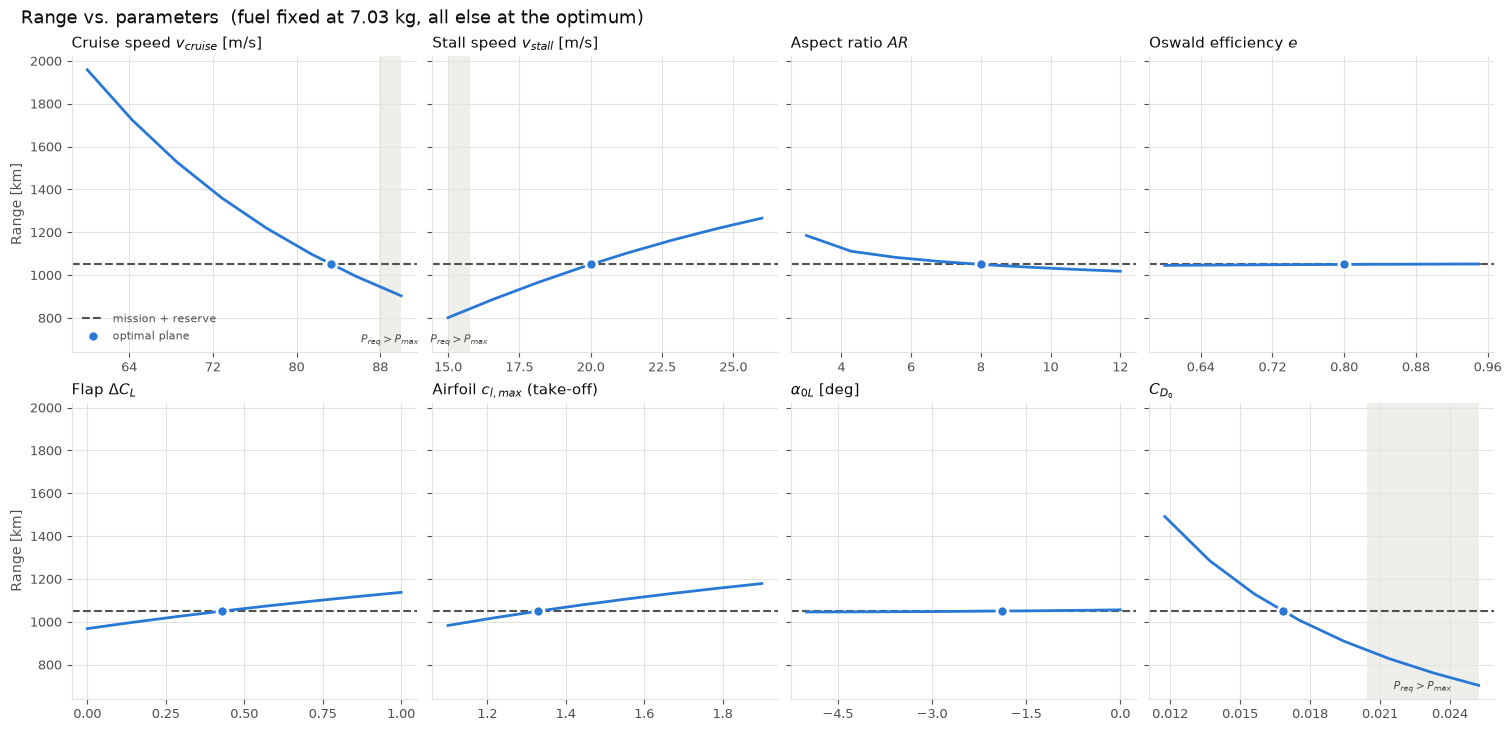

In [5]:
plot_sweeps(
    "range_km", "range_power_ok", RANGE_OPT,
    ylabel="Range [km]",
    title=f"Range vs. parameters  (fuel fixed at {FUEL_OPT:.2f} kg, all else at the optimum)",
    ref=(TARGET_KM, "mission + reserve"),
)

### Required fuel

Fuel sized for mission range + reserve, shown between 5 and 10 kg. Hollow points: cruise power required (at MTOW) exceeds $P_{max}$.

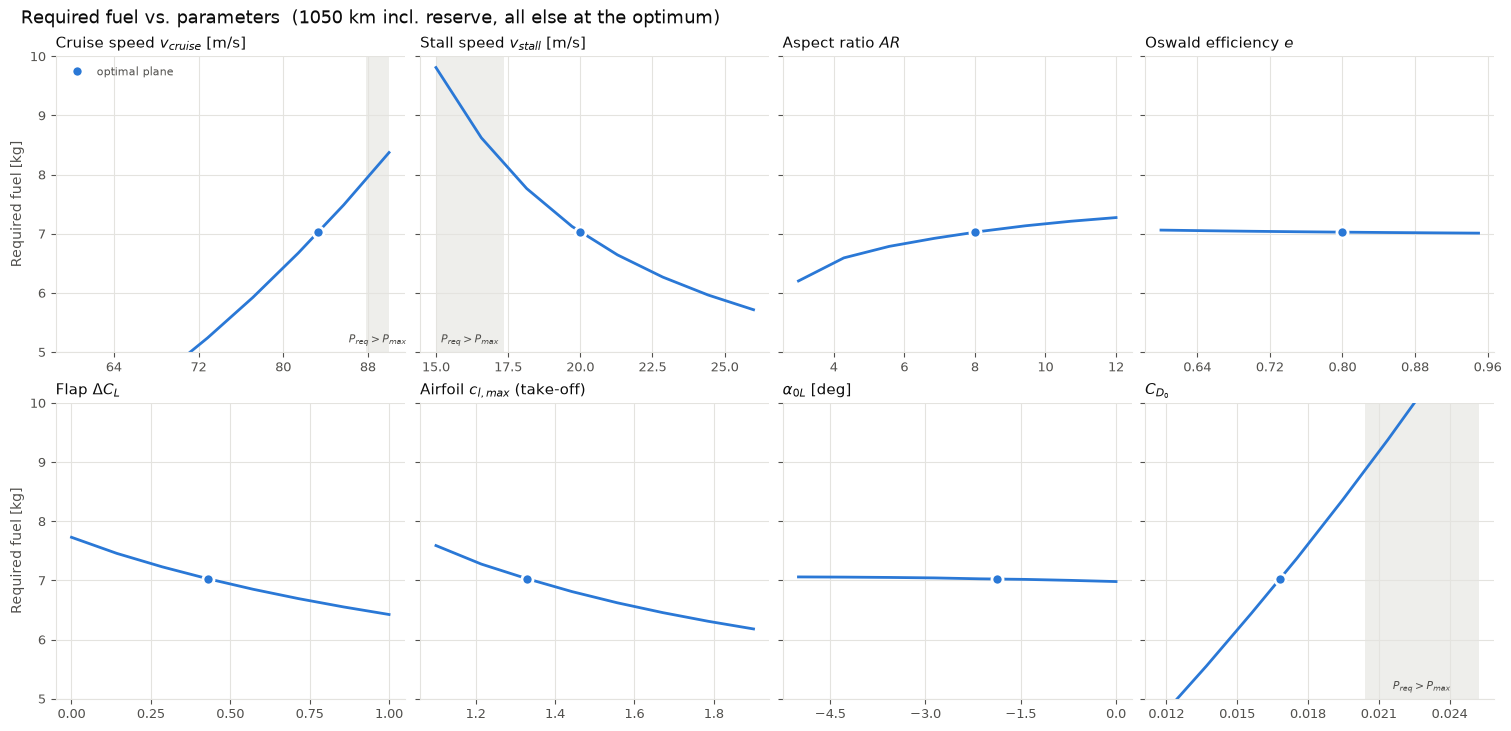

In [6]:
plot_sweeps(
    "fuel_kg", "fuel_power_ok", FUEL_OPT,
    ylabel="Required fuel [kg]",
    title=f"Required fuel vs. parameters  ({TARGET_KM:.0f} km incl. reserve, all else at the optimum)",
    ylim=FUEL_YLIM,
)

In [7]:
pd.DataFrame(
    {
        "optimum": [get_value(base_opt, p) for p in SWEEPS],
        "fuel at min [kg]": [results[p].fuel_kg.iloc[0] for p in SWEEPS],
        "fuel at max [kg]": [results[p].fuel_kg.iloc[-1] for p in SWEEPS],
        "range at min [km]": [results[p].range_km.iloc[0] for p in SWEEPS],
        "range at max [km]": [results[p].range_km.iloc[-1] for p in SWEEPS],
    },
    index=[label for label, *_ in SWEEPS.values()],
).round(3)

,optimum,fuel at min [kg],fuel at max [kg],range at min [km],range at max [km]
Cruise speed $v_{cruise}$ [m/s],83.330,3.533,8.374,1958.623,903.781
Stall speed $v_{stall}$ [m/s],20.000,9.811,5.716,801.733,1266.167
Aspect ratio $AR$,8.000,6.203,7.274,1185.093,1018.334
Oswald efficiency $e$,0.800,7.063,7.011,1045.734,1052.214
Flap $\Delta C_L$,0.430,7.730,6.425,968.460,1137.551
"Airfoil $c_{l,max}$ (take-off)",1.330,7.590,6.181,983.053,1178.630
$\alpha_{0L}$ [deg],-1.880,7.060,6.981,1046.090,1056.026
$C_{D_0}$,0.017,4.694,11.554,1491.379,703.628


### Which parameter matters most?

Elasticity at the optimum: **% change in range (fuel fixed) and in required fuel per +1 % change in the parameter** (central difference, ±1 %). Lets you compare parameters with different units. The drag iteration is converged tighter here (`abs_tol=1e-7`) so its tolerance doesn't show up as noise in the small differences.

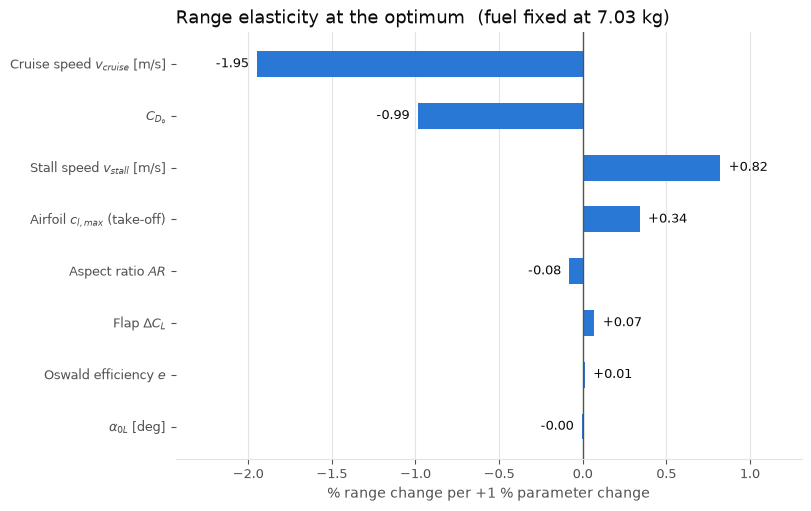

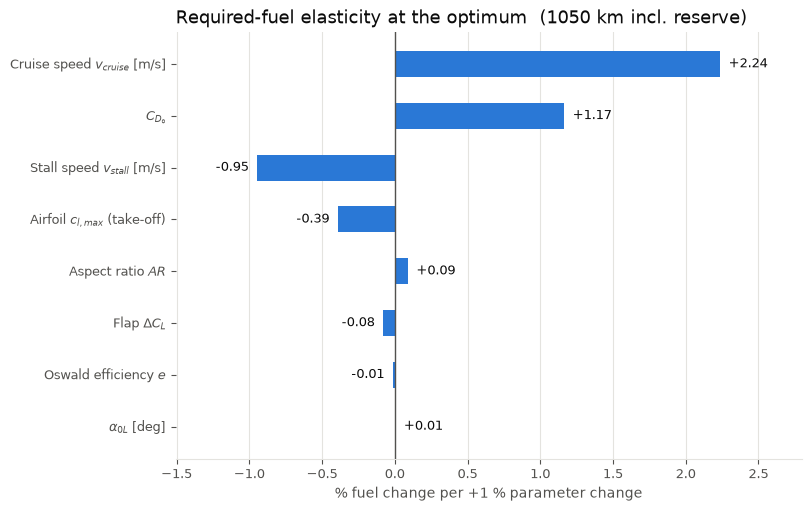

,range,fuel
Cruise speed $v_{cruise}$ [m/s],-1.946,2.237
Stall speed $v_{stall}$ [m/s],0.823,-0.946
Aspect ratio $AR$,-0.079,0.091
Oswald efficiency $e$,0.013,-0.014
Flap $\Delta C_L$,0.071,-0.081
"Airfoil $c_{l,max}$ (take-off)",0.341,-0.392
$\alpha_{0L}$ [deg],-0.004,0.005
$C_{D_0}$,-0.986,1.166


In [8]:
STEP = 0.01


def get_elasticity(path):
    # (range, fuel) elasticity at the optimum
    x0 = get_value(base_opt, path)
    tol = {} if path == "c_d_0" else {"abs_tol": 1e-7}  # c_d_0 has no drag iteration
    up = [run_case(path, x0 * (1 + STEP), fuel_mass=f, **tol) for f in (FUEL_OPT, None)]
    dn = [run_case(path, x0 * (1 - STEP), fuel_mass=f, **tol) for f in (FUEL_OPT, None)]
    if None in up + dn:
        return np.nan, np.nan
    d_range = (float(up[0].range) - float(dn[0].range)) / 1000 / RANGE_OPT
    d_fuel = (float(up[1].fuel_mass) - float(dn[1].fuel_mass)) / FUEL_OPT
    return d_range / (2 * STEP), d_fuel / (2 * STEP)


elasticity = pd.DataFrame(
    [get_elasticity(path) for path in SWEEPS],
    index=[label for label, *_ in SWEEPS.values()],
    columns=["range", "fuel"],
)


def plot_elasticity(values, xlabel, title):
    values = values.dropna().sort_values(key=np.abs)
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(values) + 1), constrained_layout=True)
    ax.barh(values.index, values.values, height=0.5, color=SERIES, zorder=2)
    ax.axvline(0, color=INK_MUTED, lw=1, zorder=3)
    for y, v in enumerate(values.values):
        ax.annotate(f"{v:+.2f}", (v, y), xytext=(6 if v >= 0 else -6, 0), textcoords="offset points",
                    ha="left" if v >= 0 else "right", va="center", color=INK, fontsize=9)
    pad = 0.25 * np.abs(values.values).max()
    ax.set_xlim(min(values.min(), 0) - pad, max(values.max(), 0) + pad)
    ax.set_xlabel(xlabel, color=INK_MUTED)
    ax.set_title(title, color=INK, fontsize=13, loc="left")
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_MUTED, labelsize=9)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    plt.show()


plot_elasticity(elasticity["range"], "% range change per +1 % parameter change",
                f"Range elasticity at the optimum  (fuel fixed at {FUEL_OPT:.2f} kg)")
plot_elasticity(elasticity["fuel"], "% fuel change per +1 % parameter change",
                f"Required-fuel elasticity at the optimum  ({TARGET_KM:.0f} km incl. reserve)")

elasticity.round(3)